# EDA: Lubbock District crash data

I need three results from the supplied CRIS export: crash counts by severity, the five most frequent contributing factors, and a time pattern. I first check what a row represents, then clean the fields those results need.

I use a few extra fields for filters and the optional map. I do not try to describe every column in the export. The raw file stays local; the outputs below show aggregate checks, not individual person records.

## 1. Read the export

The CSV starts with a disclaimer and query information, not its column header. I locate the header first. I read cells as strings so pandas does not decide which CRIS labels mean missing.

In [1]:
from pathlib import Path
import sys
import pandas as pd

# Work from either the repository root or the notebooks directory.
ROOT = Path.cwd()
if not (ROOT / "roadalyx").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from roadalyx import cris, metrics
from roadalyx.dataset import Dataset

RAW = ROOT / "data" / "raw" / "district_crashes.csv"
with RAW.open(encoding="utf-8-sig") as f:
    for header_row, line in enumerate(f):
        if line.startswith('"Crash ID"'):
            break
export = cris.read_export(RAW)
persons = export.persons
print(f"Lines before the header: {header_row}")
print(f"Rows: {len(persons):,}; columns: {len(persons.columns)}")
print(f"Header declares {export.declared_crashes:,} crashes and {export.declared_persons:,} persons.")

Lines before the header: 11
Rows: 67,906; columns: 94
Header declares 24,261 crashes and 67,906 persons.


## 2. Count crashes, not people

The export has 67,906 rows for 24,261 crashes: each row is a person involved in a crash, and the crash fields are repeated on every person row. Before keeping one row per ID, I check that the crash fields I intend to use agree across those rows. Otherwise, keeping the first row could silently select conflicting data.

In [2]:
# Count rows per crash and check that the crash fields agree inside each crash.
rows_per_crash = persons.groupby("Crash ID").size()
conflicts = cris.conflicting_crashes(persons)
print(f"Person rows: {len(persons):,}")
print(f"Distinct crashes: {len(rows_per_crash):,}")
print(f"Crashes with conflicting retained fields: {conflicts}")
assert len(persons) == export.declared_persons
assert len(rows_per_crash) == export.declared_crashes
assert conflicts == 0
rows_per_crash.value_counts().sort_index().head(6).rename_axis("Rows per crash").to_frame("Crashes")

Person rows: 67,906
Distinct crashes: 24,261
Crashes with conflicting retained fields: 0


,Crashes
Rows per crash,
1,4136
2,8757
3,5495
4,2856
5,1550
6,746


I therefore build one record per Crash ID. I do not delete person rows from the source. Identical person rows are not enough to prove that a person was recorded twice, and removing them is unnecessary for the crash metrics.

### Fields I use

These five fields are enough for the three required results:

| Field | Reason |
|---|---|
| Crash ID | Identify one crash |
| Crash Severity | Count K, A, B and C crashes |
| Contributing Factors | Rank factors once per crash |
| Crash Date | Group crashes by year and month |
| Crash Time | Group crashes by hour of the day |

I use the other fields only for the API filters, the optional map and the record view:

| Fields | Reason |
|---|---|
| County, Road Class | Filter and compare selections |
| Latitude, Longitude | Draw the optional crash map |
| Crash Death Count, Crash Suspected Serious Injury Count, Crash Total Injury Count | Separate counts of injured or killed people from crash counts |
| Speed Limit, Rural Flag, Intersection Related, At Intersection Flag | Compare road settings and intersection involvement |
| Weather Condition, Manner of Collision, First Harmful Event | Explain the recorded circumstances of a crash |
| Street Name, Construction Zone Flag, Active School Zone Flag, TxDOT Reportable Flag | Give context in the optional record view |
| Person Type | Derive whether a pedestrian, cyclist or motorcyclist was involved |

I derive the year from Crash Date, rather than relying on a separate Crash Year value. I use Person Injury Severity only as an aggregate cross-check of crash severity. I do not publish ages or individual injury tables.

In [3]:
# Check the reported crash severity against the worst recorded person injury.
crashes = persons.drop_duplicates("Crash ID").copy()
rank = {"K": 4, "A": 3, "B": 2, "C": 1, "N": 0, "9": 0}
worst = persons["Person Injury Severity"].str[0].map(rank).groupby(persons["Crash ID"]).max()
reported = crashes.set_index("Crash ID")["Crash Severity"].str[0].map(rank)
mismatches = int((worst.reindex(reported.index) != reported).sum())
print(f"Crashes whose severity differs from the worst person injury: {mismatches}")
assert mismatches == 0

Crashes whose severity differs from the worst person injury: 0


## 3. Problems I found and how I handle them

### Missing coordinates, speed codes and times

I keep crashes without coordinates in the statistics. They are excluded only from the map. A speed limit of `-1` is missing, not a negative speed. Crash Time is HHMM: `5` means 00:05, not 05:00.

In [4]:
# Count missing coordinates, unknown speed limits and invalid times; show how the flags are spelled.
coords = crashes[["Latitude", "Longitude"]].apply(pd.to_numeric, errors="coerce")
missing_location = int(coords.isna().any(axis=1).sum())
speed = pd.to_numeric(crashes["Speed Limit"], errors="coerce")
time = pd.to_numeric(crashes["Crash Time"], errors="coerce")
invalid_time = time.isna() | (time < 0) | (time > 2359) | (time % 100 > 59)
print(f"Crashes without usable coordinates: {missing_location:,}")
print(f"Unknown speed limits (-1): {int(speed.eq(-1).sum()):,}")
print(f"Missing or invalid HHMM times in this file: {int(invalid_time.sum())}")
flags = ["Rural Flag", "At Intersection Flag", "Active School Zone Flag"]
pd.DataFrame({"Field": flags, "Raw values": [", ".join(sorted(crashes[f].unique())) for f in flags]})

Crashes without usable coordinates: 849
Unknown speed limits (-1): 191
Missing or invalid HHMM times in this file: 0


,Field,Raw values
0,Rural Flag,"No, Yes"
1,At Intersection Flag,"false, true"
2,Active School Zone Flag,"NO, YES"


The flag columns use different spellings: Yes/No, true/false and YES/NO. I convert these to booleans. I also treat blank text, `NO DATA` and `NOT REPORTED` as missing.

I treat Crash ID and Crash Date more strictly, because I need them to identify a crash and place it in time. If either is missing or invalid, I stop with an error before writing the processed file. I also reject an empty export.

### Contributing factors

The same factor can appear with a leading space because the file mixes `;` and `; ` separators. I check the raw tokens before choosing the split rule.

In [5]:
# Split the factor lists naively and compare the raw tokens with the trimmed ones.
tokens = pd.Series([token for value in crashes["Contributing Factors"] for token in value.split(";")])
counts = tokens.value_counts()
print(f"Distinct tokens before trimming: {tokens.nunique()}")
print(f"Distinct tokens after trimming: {tokens.str.strip().nunique()}")
print("FAILED TO CONTROL SPEED without leading space:", int(counts.get("FAILED TO CONTROL SPEED", 0)))
print("The same factor with a leading space:", int(counts.get(" FAILED TO CONTROL SPEED", 0)))

Distinct tokens before trimming: 118
Distinct tokens after trimming: 74
FAILED TO CONTROL SPEED without leading space: 5018
The same factor with a leading space: 541


I split on `;`, normalize spaces and case, and remove repeated factors within a crash. This combines the two spellings above into one factor with 5,559 crashes.

A crash may have several factors, so its count can appear in several categories. The percentages are not parts of a single whole and do not need to add up to 100%.

I use the crash-level Contributing Factors column, not the vehicle-level Factor 1/2/3 columns. I keep `NONE` and `OTHER (EXPLAIN IN NARRATIVE)` in records but exclude them from the ranking of specific coded factors.

I do not merge similar CRIS labels into a new category. That would change the analysis, not just clean spelling.

### Cleaning decisions in one place

| Problem | What I do | Why |
|---|---|---|
| Extra lines and UTF-8 BOM before the table | Find the header and read with `utf-8-sig` | The header is not on the first line, and searching for it works whatever the length of the filter list |
| Person rows repeat crash fields | Check retained fields, then build one record per Crash ID | The results count crashes, not people |
| Spaces and separators in factor lists | Split, normalize and deduplicate within each crash | Otherwise one factor is counted as two (5,018 + 541) |
| Missing text and unknown speed limits | Store missing values rather than inventing numbers | `No Data` is not a value, and -1 is a code, not a speed |
| Different flag encodings | Convert to booleans | Yes, YES and true are the same answer |
| Case, spaces and coded weather labels | Normalize text; keep the weather description instead of its numeric prefix | The same value must not be counted under two spellings |
| HHMM time values | Derive hour and HH:MM; retain invalid optional times as unknown | `5` means 00:05, not 05:00 |
| Missing or invalid ID/date; empty export | Stop before writing | Such a record cannot be counted or placed in time |
| Missing or out-of-Texas coordinates | Leave the crash in counts, not on the map | A missing location does not remove a crash from the statistics |
| Incomplete final year/month | Mark the period as partial | So 2026 does not look like a drop in crashes |

The implementation is in [cris.py](../roadalyx/cris.py). I now use that code for the required results below, rather than maintaining another cleaning pipeline in the notebook.

## 4. Required results

### Crash counts by severity

I validate the cleaned table against the export's declared counts. I also verify that every cleaned record has a different Crash ID.

In [6]:
# Build the cleaned crash table and count crashes by severity.
records = cris.build_crashes(persons)
data = Dataset(records, {})
assert len(records) == export.declared_crashes
assert len({r["id"] for r in records}) == len(records)
print(f"Cleaned crashes: {len(records):,}")
print(f"Coverage: {data.coverage[0]} to {data.coverage[1]}")
severity = metrics.severity_counts(records)
table = pd.DataFrame(severity["severity"])[["code", "label", "crashes", "share"]].set_index("code")
table["share"] = table["share"].map("{:.1%}".format)
table.rename(columns={"label": "Severity", "crashes": "Crashes", "share": "Share of crashes"})

Cleaned crashes: 24,261
Coverage: 2020-01-01 to 2026-10-20


,Severity,Crashes,Share of crashes
code,,,
K,Fatal injury,624,2.6%
A,Suspected serious injury,1546,6.4%
B,Suspected minor injury,7224,29.8%
C,Possible injury,14867,61.3%


### Top five contributing factors

I count whether each factor is recorded for a crash, not how many person rows repeat it. A recorded factor is not proof of causation.

In [7]:
# Rank the contributing factors, each counted once per crash.
top = metrics.top_factors(records, limit=5)
print(f"Crashes with no specific coded factor: {top['crashes_without_coded_factor']:,}")
table = pd.DataFrame(top["factors"])[["rank", "factor", "crashes", "share"]].set_index("rank")
table["share"] = table["share"].map("{:.1%}".format)
table.rename(columns={"factor": "Factor", "crashes": "Crashes", "share": "Share of crashes"})

Crashes with no specific coded factor: 1,018


,Factor,Crashes,Share of crashes
rank,,,
1,FAILED TO CONTROL SPEED,5559,22.9%
2,FAILED TO YIELD RIGHT OF WAY - STOP SIGN,2428,10.0%
3,FAILED TO YIELD RIGHT OF WAY - TURNING LEFT,2346,9.7%
4,FAILED TO DRIVE IN SINGLE LANE,2334,9.6%
5,UNSAFE SPEED,2034,8.4%


### Time pattern

I use years for the required time summary. The file ends on 20 October 2026, so I do not compare that year directly with a complete year.

In [8]:
# Count crashes per year; 2026 is marked as a partial year.
years = pd.DataFrame(metrics.trend(records, "year", data.coverage)["buckets"])
years[["label", "crashes", "complete"]].rename(columns={"label": "Year", "complete": "Full year"}).set_index("Year")

,crashes,Full year
Year,,
2020,3351,True
2021,3971,True
2022,3716,True
2023,3673,True
2024,3452,True
2025,3444,True
2026,2654,False


### Cross-check the totals

I check that severity and time groupings account for every crash. For the hour axis, crashes with missing times belong in the unknown count, not in hour zero.

In [9]:
# Check that every grouping adds back up to the total number of crashes.
assert sum(s["crashes"] for s in severity["severity"]) == len(records)
for axis in ("year", "month", "hour", "weekday"):
    result = metrics.trend(records, axis, data.coverage)
    assert sum(b["crashes"] for b in result["buckets"]) + result["unknown"] == len(records)
located = sum(r["lat"] is not None and r["lon"] is not None for r in records)
assert located + missing_location == len(records)
print(f"All groupings reconcile to {len(records):,} crashes.")
print(f"Map: {located:,} located; {missing_location:,} retained in counts without a location.")

All groupings reconcile to 24,261 crashes.
Map: 23,412 located; 849 retained in counts without a location.


## 5. Additional analyst views

These are supporting checks for the optional Explorer, not extra requirements. I look at monthly counts and hours to show what an analyst can query beyond the yearly summary.

Lowest complete month: Apr 2020, 175 crashes


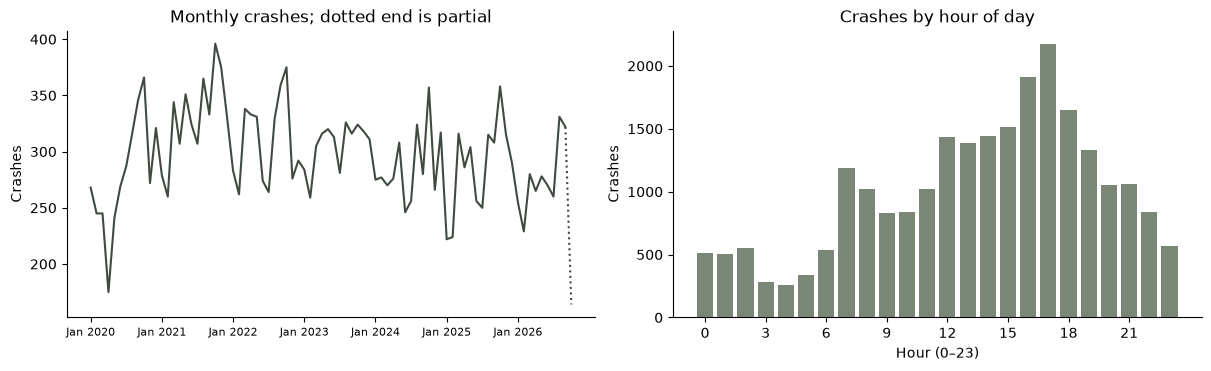

In [10]:
# Plot monthly and hourly counts as two separate charts.
import matplotlib.pyplot as plt

months = pd.DataFrame(metrics.trend(records, "month", data.coverage)["buckets"])
hours = pd.DataFrame(metrics.trend(records, "hour", data.coverage)["buckets"])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), layout="constrained")
full = months[months["complete"]]
axes[0].plot(full.index, full["crashes"], color="#414a40")
axes[0].plot(months.index[-2:], months["crashes"].iloc[-2:], color="#414a40", linestyle=":")
axes[0].set_xticks(range(0, len(months), 12), months["label"].iloc[::12], fontsize=8)
axes[0].set_title("Monthly crashes; dotted end is partial")
axes[0].set_ylabel("Crashes")
axes[1].bar(hours["key"], hours["crashes"], color="#7a8776")
axes[1].set_xticks(range(0, 24, 3))
axes[1].set_title("Crashes by hour of day")
axes[1].set_xlabel("Hour (0–23)")
axes[1].set_ylabel("Crashes")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
lowest = full.loc[full["crashes"].idxmin()]
print(f"Lowest complete month: {lowest['label']}, {int(lowest['crashes'])} crashes")
plt.show()

I compare the share of recorded injury crashes classified as fatal or serious (K or A) in urban and rural areas. This is not an estimate of risk per trip.

In [11]:
# Compare the fatal-or-serious (K+A) share in urban and rural areas.
frame = pd.DataFrame(records)
frame["fatal_or_serious"] = frame["severity"].isin(["K", "A"])
summary = frame.groupby("rural")["fatal_or_serious"].agg(crashes="size", share="mean")
summary = summary.rename(index={False: "Urban", True: "Rural"}).rename_axis("Area")
summary["share"] = summary["share"].map("{:.1%}".format)
summary.rename(columns={"crashes": "Injury crashes", "share": "Fatal or serious share"})

,Injury crashes,Fatal or serious share
Area,,
Urban,18893,4.8%
Rural,5368,23.5%


## 6. What I can conclude, and what I cannot

- Failed to control speed is the most frequently recorded specific factor: 5,559 crashes, about 23% of this export. Frequency does not make it the most severe factor or establish causation.
- Yearly counts vary rather than showing a steady rise or fall. I keep incomplete 2026 separate from full-year comparisons.
- Rural injury crashes have a higher fatal-or-serious share in this data. I cannot turn that into a crash rate without traffic exposure.
- April 2020 is the lowest complete month, with 175 crashes. This file alone does not explain why it was lower.

The export excludes property-damage-only crashes. Recent reports may still be added. Without traffic volumes or miles traveled, I cannot calculate crash rates. I keep those limits in the interpretation rather than adding unsupported conclusions.

The API uses the same [metric functions](../roadalyx/metrics.py). [Pipeline tests](../tests/test_pipeline.py) cover cleaning and validation, including invalid required fields and preserving an existing output file on validation failure.